# ÉcoBâti — consommation énergétique du parc

Quels bâtiments et usages méritent un diagnostic énergétique après prise en compte de la surface et de la météo ?

Projet personnel sur données synthétiques. Exécuter les cellules dans l’ordre : simulation, contrôle qualité, calculs, interprétation et rapport.

In [1]:
from pathlib import Path
import os, sqlite3, textwrap
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Retrouver le dossier du projet depuis sa racine ou le dossier notebooks.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data/raw').is_dir())
RAW, CLEAN, OUT, REPORT = [ROOT / p for p in ['data/raw', 'data/processed', 'analysis', 'reports']]
for directory in [RAW, CLEAN, OUT, REPORT, ROOT / 'docs']:
    directory.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261010)
AUDIT, DICT, FIGS, SECTIONS = [], [], [], []
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
def csv(df, file):
    df.to_csv(file, sep=";", index=False, encoding="utf-8-sig", float_format="%.8f")

def finish(title, question, metrics, tables, findings, actions, limits):
    """Exporter des résultats ouverts et préparer la restitution sans page web."""
    global METRICS, TITLE, QUESTION, FINDINGS, ACTIONS, LIMITS
    TITLE, QUESTION, METRICS = title, question, metrics
    FINDINGS, ACTIONS = findings, actions
    LIMITS = [s for s in limits if not any(w in s.lower() for w in ['natif', 'html', 'guide'])]
    csv(pd.DataFrame(AUDIT), OUT / 'qualite.csv')
    csv(pd.DataFrame(DICT), ROOT / 'docs/dictionnaire.csv')
    indicators = pd.DataFrame({'indicateur': metrics.keys(), 'valeur': list(metrics.values())})
    csv(indicators, OUT / 'indicateurs.csv')
    for name, table in tables.items():
        csv(table, OUT / (name + '.csv'))
    display(Markdown('## Résultats recalculés'))
    display(indicators)
    for item in findings:
        display(Markdown('- ' + item))
    from IPython.display import Image
    for name, fig in FIGS:
        display(Image(filename=str(REPORT / (name + '.png'))))
    plt.close('all')

class Restitution:
    """Relier les résultats calculés aux interprétations et aux recommandations."""
    def __init__(self):
        self.root = ROOT
        self.m = METRICS
        self.resume, self.actions = [], []
    def read(self, name):
        return pd.read_csv(ROOT / name, sep=';')
    def number(self, value, decimals=0):
        return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
    def pct(self, value, decimals=1):
        return self.number(value * 100, decimals) + ' %'
    def money(self, value, decimals=0):
        return self.number(value, decimals) + ' EUR'
    def section(self, title, paragraphs, tables=None):
        SECTIONS.append((title, paragraphs))
        display(Markdown('## ' + title + '\n\n' + '\n\n'.join(paragraphs)))
        for label, table in (tables or []):
            display(Markdown('### ' + label))
            display(table.head(30))


In [3]:
TITLE_INIT = 'ÉcoBâti — consommation énergétique du parc'
QUESTION_INIT = 'Quels bâtiments et usages méritent un diagnostic énergétique après prise en compte de la surface et de la météo ?'

## Construire un panel mensuel documenté

In [4]:
# 120 bâtiments sur 36 mois ; une ligne = un bâtiment et un mois.
buildings = pd.DataFrame({'Batiment_ID': [f'B{i:03d}' for i in range(120)], 'Ville': RNG.choice(['Lille', 'Lyon', 'Nantes', 'Toulouse'], 120), 'Usage': RNG.choice(['Bureaux', 'Ecole', 'Gymnase'], 120), 'Surface_m2': RNG.integers(600, 8000, 120)})
dates = pd.DataFrame({'Date': pd.date_range('2023-01-01', periods=36, freq='MS')})
df = buildings.merge(dates, how='cross')
df['DJU'] = np.maximum(15, 170 + 160*np.cos(2*np.pi*(df.Date.dt.month-1)/12) + RNG.normal(0, 18, len(df))).round(1)
effect = df.Usage.map({'Bureaux': 4.5, 'Ecole': 3.6, 'Gymnase': 6.0})
df['Consommation_kwh'] = (df.Surface_m2*(effect + .035*df.DJU)*RNG.lognormal(0, .10, len(df))).round(1)
df['Annee'], df['Mois'] = df.Date.dt.year, df.Date.dt.strftime('%Y-%m')
df.loc[:9, 'Consommation_kwh'] = -1
df = pd.concat([df, df.iloc[200:225]], ignore_index=True)
csv(df, RAW / 'consommations.csv')
display(df.head())

  Batiment_ID  Ville  Usage  Surface_m2       Date    DJU  Consommation_kwh  \
0        B000  Lille  Ecole        3681 2023-01-01  336.0              -1.0   
1        B000  Lille  Ecole        3681 2023-02-01  329.7              -1.0   
2        B000  Lille  Ecole        3681 2023-03-01  257.6              -1.0   
3        B000  Lille  Ecole        3681 2023-04-01  186.9              -1.0   
4        B000  Lille  Ecole        3681 2023-05-01   98.0              -1.0   

   Annee     Mois  
0   2023  2023-01  
1   2023  2023-02  
2   2023  2023-03  
3   2023  2023-04  
4   2023  2023-05  

## Contrôler le grain et les unités

In [5]:
dup = df.duplicated(['Batiment_ID', 'Date'])
unique = df.loc[~dup].copy()
valid = unique.Consommation_kwh.ge(0) & unique.Surface_m2.gt(0) & unique.DJU.gt(0)
v = unique.loc[valid].copy()
csv(df.loc[dup], OUT / 'doublons.csv')
csv(unique.loc[~valid], OUT / 'rejets.csv')
AUDIT.append({'table': 'consommations', 'brut': len(df), 'doublons': int(dup.sum()), 'rejets': int((~valid).sum()), 'propre': len(v)})
assert len(df) == int(dup.sum()) + int((~valid).sum()) + len(v)
assert not v.duplicated(['Batiment_ID', 'Date']).any()
v['Intensite_kwh_m2'] = v.Consommation_kwh/v.Surface_m2
# Ce ratio est une approximation descriptive ; le chauffage et les usages de base sont confondus.
v['Intensite_par_dju'] = v.Intensite_kwh_m2/v.DJU
csv(v, CLEAN / 'consommations.csv')

## Comparer les intensités à surface et période explicites

In [6]:
annual = v.groupby('Annee').agg(Consommation_kwh=('Consommation_kwh', 'sum'), Surface_mois_m2=('Surface_m2', 'sum'), Observations=('Batiment_ID', 'size')).reset_index()
annual['Intensite_mensuelle_ponderee'] = annual.Consommation_kwh/annual.Surface_mois_m2
monthly = v.groupby('Mois').agg(Consommation_kwh=('Consommation_kwh', 'sum'), Surface_m2=('Surface_m2', 'sum'), DJU_moyen=('DJU', 'mean')).reset_index()
monthly['Intensite_kwh_m2'] = monthly.Consommation_kwh/monthly.Surface_m2
usage = v.groupby('Usage').agg(Consommation_kwh=('Consommation_kwh', 'sum'), Surface_mois_m2=('Surface_m2', 'sum')).reset_index()
usage['Intensite_kwh_m2'] = usage.Consommation_kwh/usage.Surface_mois_m2
ranking = v.groupby(['Batiment_ID', 'Ville', 'Usage']).agg(Intensite_moyenne=('Intensite_kwh_m2', 'mean'), Ratio_DJU=('Intensite_par_dju', 'mean'), Mois_observes=('Date', 'size')).reset_index()
ranking['Rang_usage'] = ranking.groupby('Usage').Ratio_DJU.rank(ascending=False, method='min')
assert np.isclose(annual.Consommation_kwh.sum(), v.Consommation_kwh.sum())
display(annual)
display(ranking.sort_values(['Usage', 'Rang_usage']).head(20))

   Annee  Consommation_kwh  Surface_mois_m2  Observations  \
0   2023        63339425.0          5903394          1430   
1   2024        63871761.9          5940204          1440   
2   2025        64106242.5          5940204          1440   

   Intensite_mensuelle_ponderee  
0                     10.729324  
1                     10.752453  
2                     10.791926  

    Batiment_ID     Ville    Usage  Intensite_moyenne  Ratio_DJU  \
40         B040  Toulouse  Bureaux          10.573063   0.119267   
52         B052    Nantes  Bureaux          10.634119   0.116244   
14         B014     Lille  Bureaux          10.623235   0.113491   
58         B058    Nantes  Bureaux          10.935474   0.111885   
110        B110      Lyon  Bureaux          10.619776   0.111304   
1          B001  Toulouse  Bureaux          10.290956   0.110920   
77         B077      Lyon  Bureaux          10.160972   0.109838   
103        B103    Nantes  Bureaux          10.594914   0.109724   
5          B005     Lille  Bureaux          10.589566   0.109156   
24         B024     Lille  Bureaux          10.416086   0.108350   
98         B098      Lyon  Bureaux          10.636745   0.107812   
64         B064     Lille  Bureaux          10.391403   0.107299   
12         B012      Lyon  Bureaux          10.614254   0.105488   
3          B003     Lille  Bureaux          10.6

## Restituer les tendances et les investigations

## Résultats recalculés

                     indicateur        valeur
0                  observations  4.310000e+03
1                     batiments  1.200000e+02
2       consommation_totale_kwh  1.913174e+08
3  intensite_mensuelle_ponderee  1.075796e+01
4               mois_incomplets  1.000000e+01

- 120 bâtiments ; 4310 observations mensuelles valides.

- Intensité mensuelle pondérée : 10.76 kWh/m².

- 10 mois ont une couverture incomplète après exclusions.

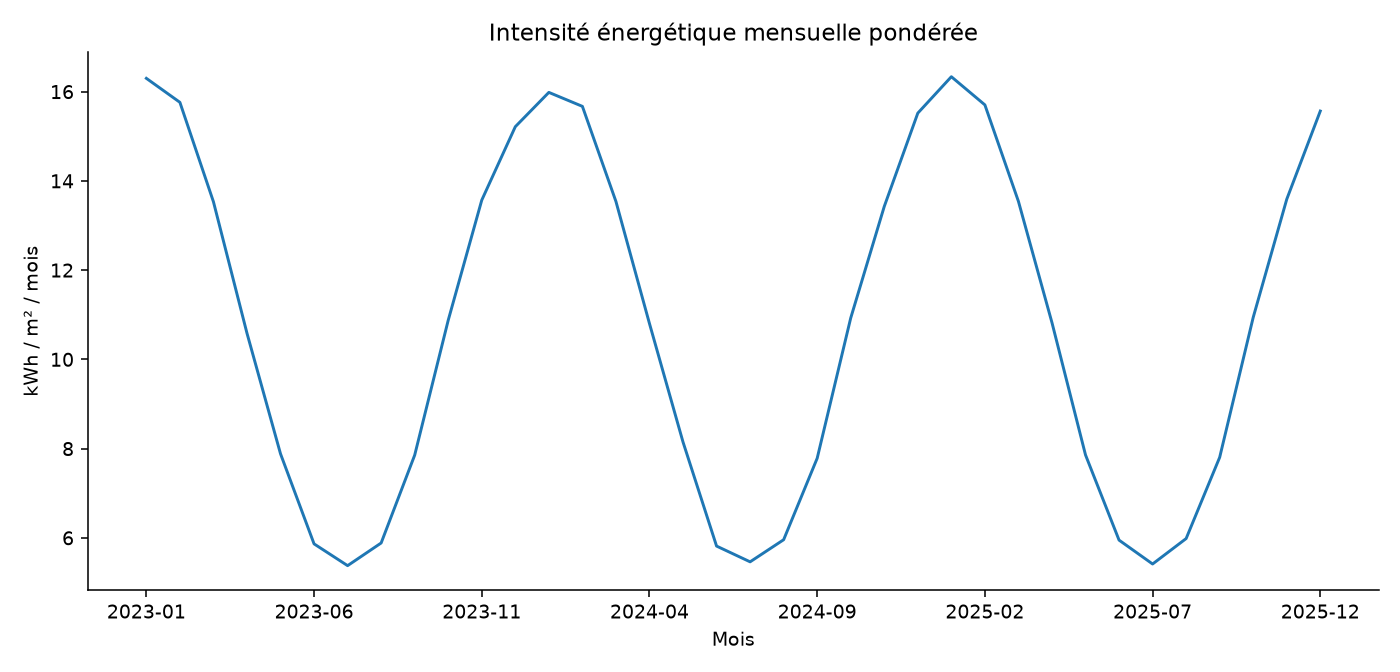

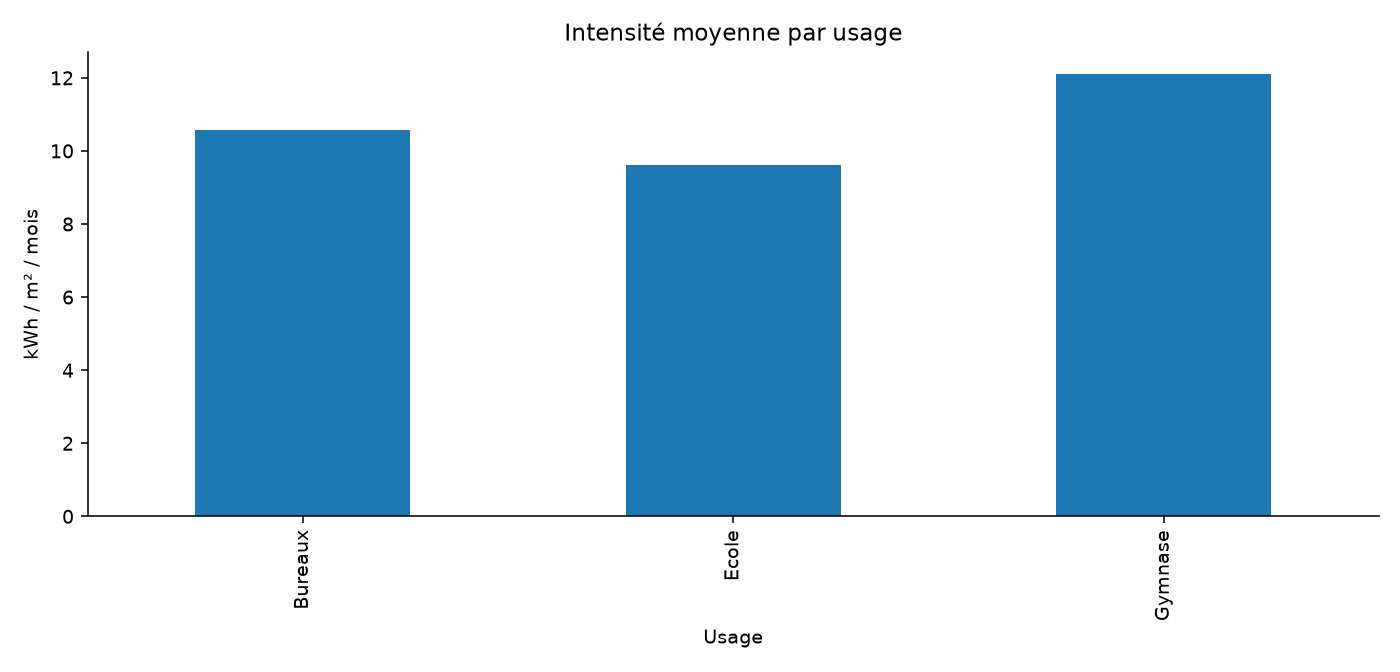

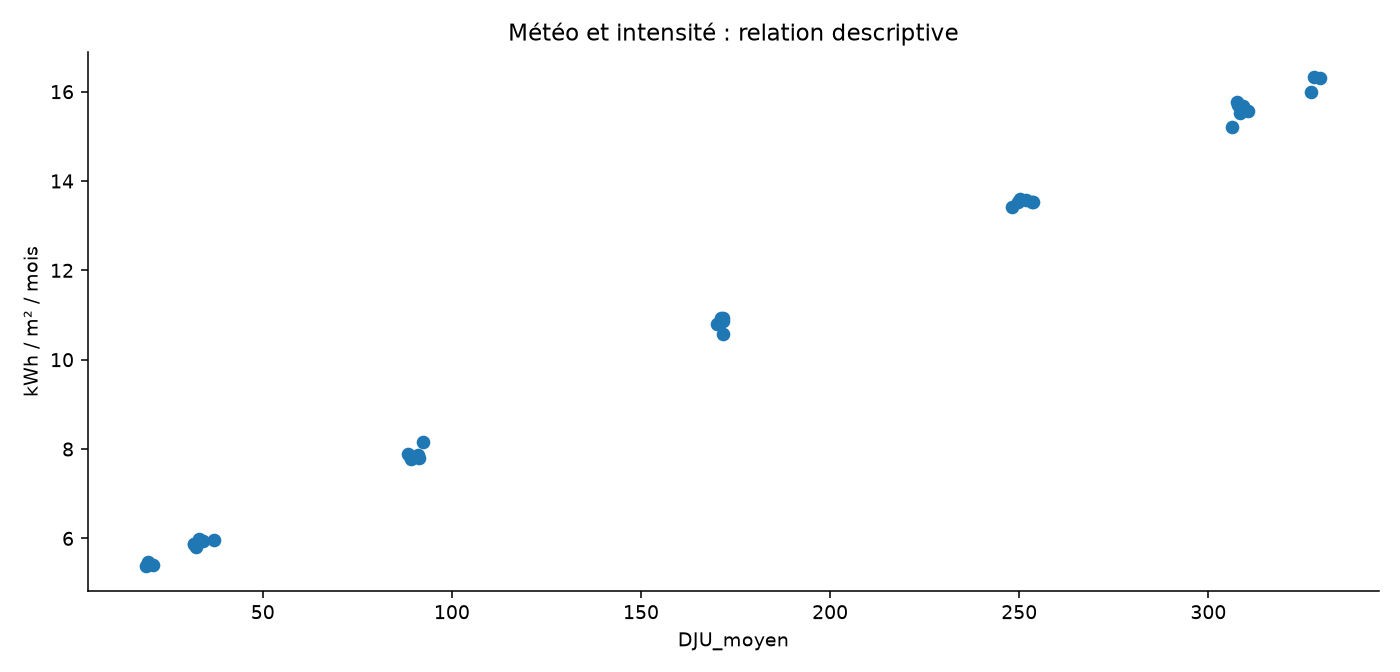

In [7]:
for name, table, x, y, title in [('intensite_mensuelle', monthly, 'Mois', 'Intensite_kwh_m2', 'Intensité énergétique mensuelle pondérée'), ('comparaison_usages', usage, 'Usage', 'Intensite_kwh_m2', 'Intensité moyenne par usage'), ('meteo_consommation', monthly, 'DJU_moyen', 'Intensite_kwh_m2', 'Météo et intensité : relation descriptive')]:
    fig, ax = plt.subplots()
    if x == 'DJU_moyen':
        ax.scatter(table[x], table[y])
    else:
        table.plot(x=x, y=y, ax=ax, kind='bar' if x=='Usage' else 'line', legend=False)
    ax.set_title(title)
    ax.set_xlabel(x)
    ax.set_ylabel('kWh / m² / mois')
    fig.tight_layout()
    fig.savefig(REPORT / (name+'.png'), dpi=140)
    FIGS.append((name, fig))
metrics = {'observations': len(v), 'batiments': v.Batiment_ID.nunique(), 'consommation_totale_kwh': v.Consommation_kwh.sum(), 'intensite_mensuelle_ponderee': v.Consommation_kwh.sum()/v.Surface_m2.sum(), 'mois_incomplets': int((monthly.Surface_m2 < buildings.Surface_m2.sum()).sum())}
finish(TITLE_INIT, QUESTION_INIT, metrics, {'annuel': annual, 'mensuel': monthly, 'usages': usage, 'priorites': ranking}, [f"{metrics['batiments']} bâtiments ; {len(v)} observations mensuelles valides.", f"Intensité mensuelle pondérée : {metrics['intensite_mensuelle_ponderee']:.2f} kWh/m².", f"{metrics['mois_incomplets']} mois ont une couverture incomplète après exclusions."], ['Investiguer les bâtiments les plus intenses au sein d’un même usage.', 'Vérifier les compteurs, occupations et surfaces avant tout classement définitif.', 'Construire ensuite un modèle de chauffage séparant usages de base et météo.'], ['Données entièrement fictives ; DJU simulés.', 'Les ratios ne constituent ni un DPE ni un audit réglementaire.', 'Le ratio par DJU ne sépare pas le chauffage des autres consommations.', 'Aucune économie réelle ni réduction de CO₂ n’est démontrée.'])

## Rapport PowerPoint modifiable

Les indicateurs et les graphiques calculés alimentent cette présentation. Les graphiques sont des images et les textes restent modifiables.

In [8]:
# Créer un vrai fichier PowerPoint : titres et textes restent modifiables.
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

presentation = Presentation()
presentation.core_properties.author = 'Imad Kaanane'
presentation.core_properties.last_modified_by = 'Imad Kaanane'
presentation.core_properties.title = ROOT.name
presentation.core_properties.subject = 'Analyse de données — projet personnel sur données synthétiques'
presentation.slide_width, presentation.slide_height = Inches(13.333), Inches(7.5)

def slide_text(title, lines):
    slide = presentation.slides.add_slide(presentation.slide_layouts[6])
    background = slide.background.fill
    background.solid()
    background.fore_color.rgb = RGBColor(245, 248, 251)
    heading = slide.shapes.add_textbox(Inches(.65), Inches(.4), Inches(12), Inches(.85)).text_frame
    heading.text = title
    heading.paragraphs[0].font.size = Pt(28 if len(title) < 65 else 22)
    heading.paragraphs[0].font.bold = True
    heading.paragraphs[0].font.color.rgb = RGBColor(20, 80, 95)
    body = slide.shapes.add_textbox(Inches(.7), Inches(1.5), Inches(11.9), Inches(5.2)).text_frame
    body.word_wrap = True
    for i, line in enumerate(lines):
        paragraph = body.paragraphs[0] if i == 0 else body.add_paragraph()
        paragraph.text = str(line)
        paragraph.font.size = Pt(20 if sum(len(str(x)) for x in lines) < 750 else 16)
        paragraph.space_after = Pt(18)
    footer = slide.shapes.add_textbox(Inches(.7), Inches(7.05), Inches(12), Inches(.25)).text_frame
    footer.text = 'Simulation pédagogique • données synthétiques • ' + str(len(presentation.slides))
    footer.paragraphs[0].font.size = Pt(10)
    return slide

slide_text(TITLE, [QUESTION, 'Analyse reproductible dans Jupyter ; présentation modifiable.', 'Données fictives : aucune mission réelle ni effet causal démontré.'])
slide_text('Question et méthode', [QUESTION, 'Contrôler les clés, les doublons et les valeurs invalides avant les agrégations.', 'Lire les unités et les hypothèses du notebook avant de comparer les résultats.'])
slide_text('Qualité des données', [str(row) for row in AUDIT] or ['Contrôles documentés dans le notebook.'])
items = [str(k).replace('_', ' ') + ' : ' + (f'{float(v):,.4f}' if isinstance(v, (float, np.floating)) else str(v)) for k, v in METRICS.items()]
for start in range(0, len(items), 7):
    slide_text('Indicateurs recalculés', items[start:start + 7])
slide_text('Résultats à retenir', FINDINGS)
for name, _ in FIGS:
    slide = slide_text(name.replace('_', ' ').capitalize(), [])
    slide.shapes.add_picture(str(REPORT / (name + '.png')), Inches(1), Inches(1.45), width=Inches(11.3), height=Inches(5.35))
for title, paragraphs in SECTIONS:
    slide_text(title, paragraphs[:2])
slide_text('Actions proposées', ACTIONS)
slide_text('Limites et prochaines étapes', LIMITS + ['Adapter les hypothèses et valider sur des données réelles avant toute décision.'])
target = ROOT / 'presentation' / 'soutenance.pptx'
target.parent.mkdir(exist_ok=True)
presentation.save(target)
summary = ['# ' + TITLE, '', QUESTION, '', '## Résultats'] + ['- ' + s for s in FINDINGS] + ['', '## Actions'] + ['- ' + s for s in ACTIONS] + ['', '## Limites'] + ['- ' + s for s in LIMITS]
(OUT / 'SYNTHESE.md').write_text('\n'.join(summary) + '\n', encoding='utf-8')
print('Présentation enregistrée :', target.relative_to(ROOT))


Présentation enregistrée : presentation\soutenance.pptx
